## **Environment Setup & Package Installation**

In [ ]:
%%capture
!pip install -U ipython -q
!pip install ultralytics grad-cam -q

from kaggle_secrets import UserSecretsClient 
gh_token = UserSecretsClient().get_secret("GH_TOKEN")
!git clone https://{gh_token}@github.com/Hannysia/drone_detection.git
!pip install -e drone_detection/
%cd /kaggle/working/drone_detection

%load_ext autoreload
%autoreload 2

In [ ]:
import os
import logging
import yaml
from pathlib import Path
from huggingface_hub import HfApi
from src.config import EXTRACTED_DATA_DIR, WORKING_DIR, OUTPUT_DIR
from src.processing.training import run_full_pipeline
from src.processing.diagnostics import run_shortcut_analysis

logging.basicConfig(level=logging.INFO, format='%(message)s')
log = logging.getLogger(__name__)

DEFAULT_MODEL_TYPE = "yolo26n.pt"
IMGSZ = 1280
EPOCHS = 50
BATCH_SIZE = 8
PATIENCE = 15


## **Execution Block**

### **Positives-Only**


[DATA PREPARATION] Setting up dataset directories for run: run_positives_only
[TRAIN] Symlinked 8,177 positives and 0 negatives.
[VAL] Symlinked 6,035 positives and 0 negatives.
[DATA PREPARATION] Created YAML configuration at: /kaggle/working/dataset_run_positives_only.yaml

STARTING YOLO TRAINING RUN: RUN_POSITIVES_ONLY
Loading weights: yolo26n.pt
Ultralytics 8.4.68 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=True, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/dataset_run_positives_only.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=25, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

[SUCCESS] Checkpoint successfully uploaded to Hugging Face.

STARTING SHORTCUT ANALYSIS FOR: RUN_POSITIVES_ONLY
[INFO] Attempting download from HF Hub: models/yolo26n_run_positives_only_best.pt


models/yolo26n_run_positives_only_best.p(…):   0%|          | 0.00/5.50M [00:00<?, ?B/s]

[SUCCESS] Weights downloaded to secure cache: /root/.cache/huggingface/hub/datasets--hannusia123123--drone_dataset/snapshots/d231232d39cb04812c8ce445d46cfd16511b6027/models/yolo26n_run_positives_only_best.pt
[EVAL] Model loaded from: /root/.cache/huggingface/hub/datasets--hannusia123123--drone_dataset/snapshots/d231232d39cb04812c8ce445d46cfd16511b6027/models/yolo26n_run_positives_only_best.pt
[EVAL] Parameters: 2,504,190
[EVAL] SPPF layer dynamically found at index 9
[INFO] Sampling 10 frames for analysis.


Generating Visualizations:   0%|          | 0/10 [00:00<?, ?it/s]

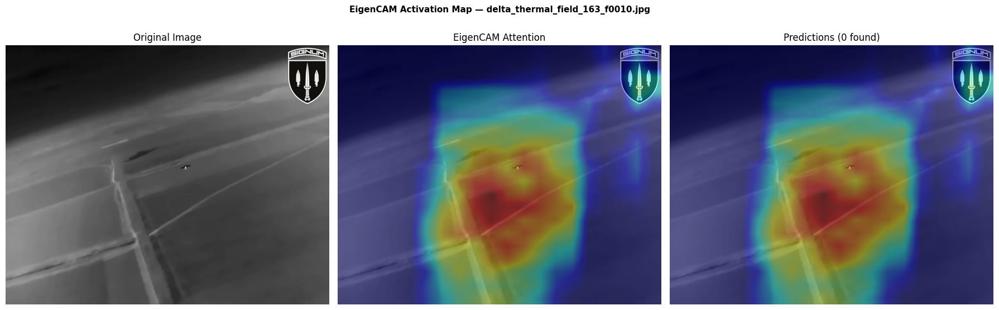

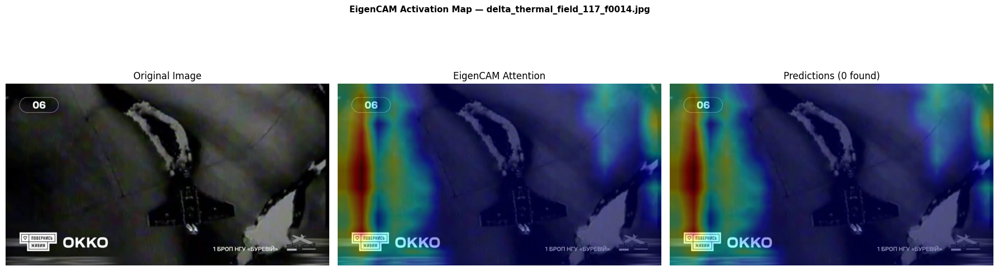

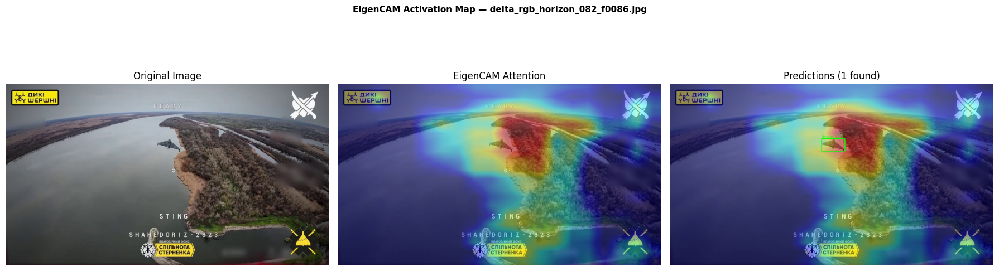

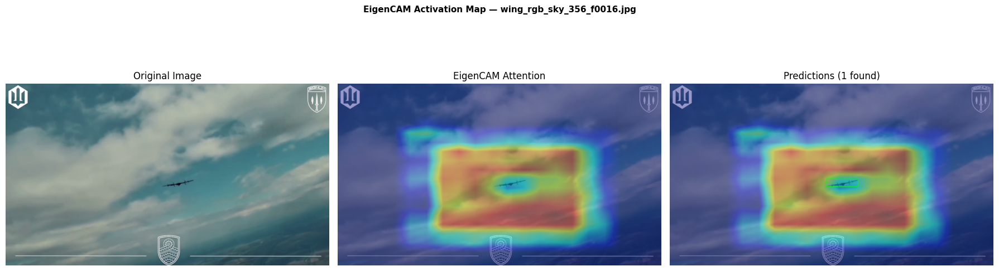

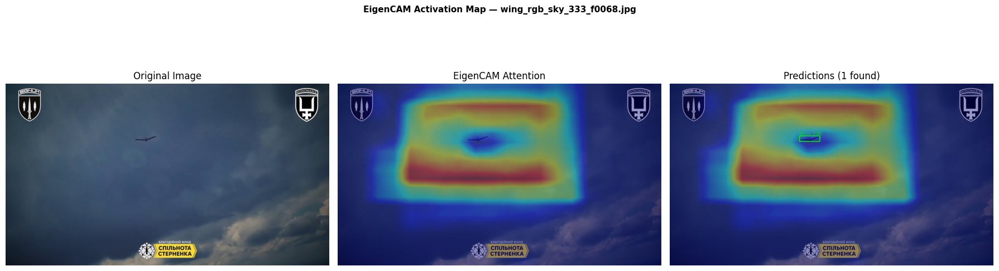

...

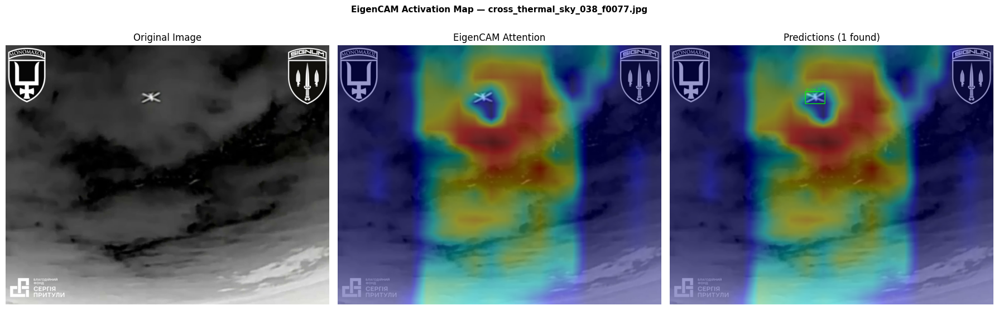

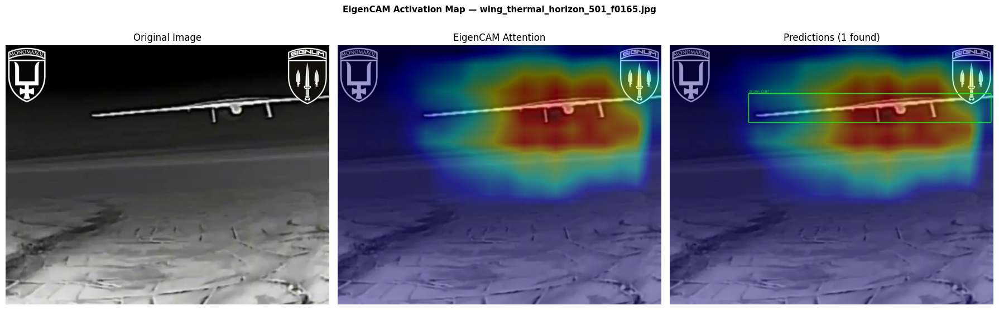

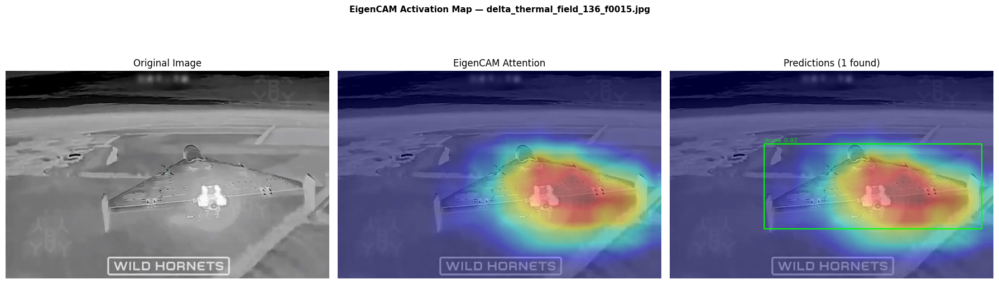

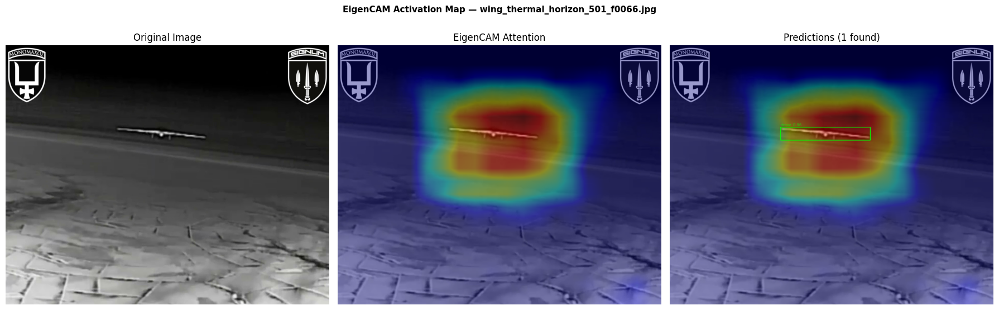

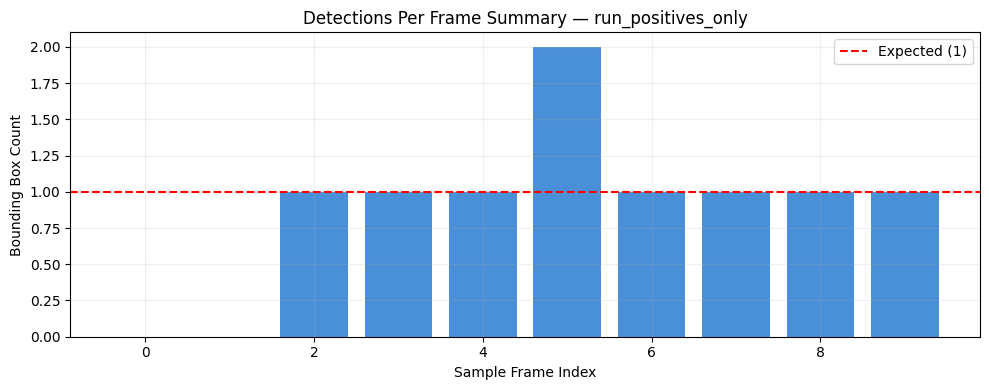


ANALYSIS REPORT: RUN_POSITIVES_ONLY
Frames Analyzed:            10
Average Detections/Frame:   0.90
Missed Objects:             2
Artifacts Saved To:         /kaggle/working/analysis_results/run_positives_only


In [ ]:
# ==========================================
# RUN 1: Positives-Only Dataset
# ==========================================

run_name_1 = "run_positives_only"

best_weights_1 = run_full_pipeline(
    use_negatives=False, 
    run_name=run_name_1,
    epochs=25,
    imgsz=IMGSZ,
    batch=BATCH_SIZE,
    patience=PATIENCE
)

val_dir_1 = WORKING_DIR / f"yolo_dataset_{run_name_1}" / "images" / "val"
run_shortcut_analysis(
    weights_path=str(best_weights_1),
    val_dir=str(val_dir_1),
    output_dir_path="/kaggle/working/analysis_results",
    run_name=run_name_1,
    n_images=10,
    conf_thresh=0.25
)

### **Positives + Negatives**


[DATA PREPARATION] Setting up dataset directories for run: run_with_negatives
[TRAIN] Symlinked 8,177 positives and 810 negatives.
[VAL] Symlinked 6,035 positives and 1,047 negatives.
[DATA PREPARATION] Created YAML configuration at: /kaggle/working/dataset_run_with_negatives.yaml

STARTING YOLO TRAINING RUN: RUN_WITH_NEGATIVES
Loading weights: yolo26n.pt
Ultralytics 8.4.68 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=True, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/dataset_run_with_negatives.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=25, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, 

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

[SUCCESS] Checkpoint successfully uploaded to Hugging Face.

STARTING SHORTCUT ANALYSIS FOR: RUN_WITH_NEGATIVES
[INFO] Attempting download from HF Hub: models/yolo26n_run_with_negatives_best.pt


models/yolo26n_run_with_negatives_best.p(…):   0%|          | 0.00/5.50M [00:00<?, ?B/s]

[SUCCESS] Weights downloaded to secure cache: /root/.cache/huggingface/hub/datasets--hannusia123123--drone_dataset/snapshots/33e104a6f7cd3c02a71708923a5cf03b7859f84d/models/yolo26n_run_with_negatives_best.pt
[EVAL] Model loaded from: /root/.cache/huggingface/hub/datasets--hannusia123123--drone_dataset/snapshots/33e104a6f7cd3c02a71708923a5cf03b7859f84d/models/yolo26n_run_with_negatives_best.pt
[EVAL] Parameters: 2,504,190
[EVAL] SPPF layer dynamically found at index 9
[INFO] Sampling 10 frames for analysis.


Generating Visualizations:   0%|          | 0/10 [00:00<?, ?it/s]

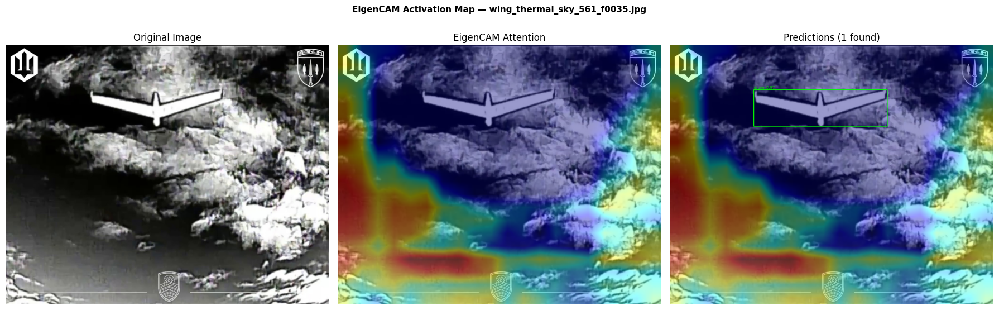

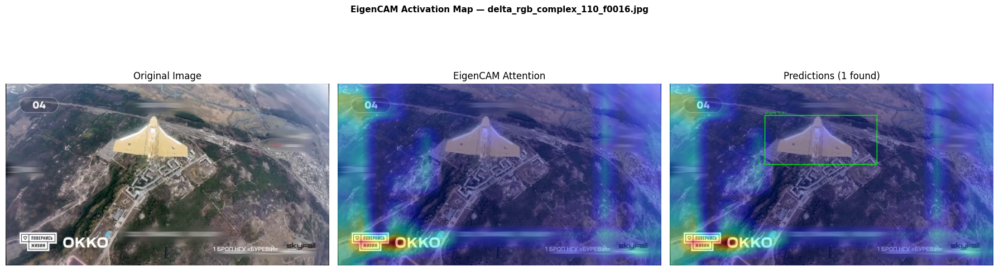

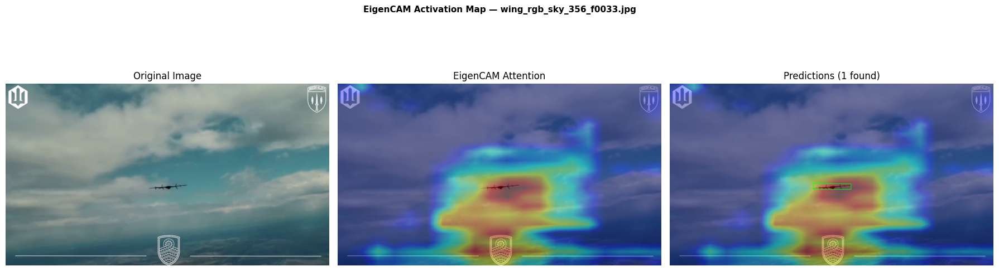

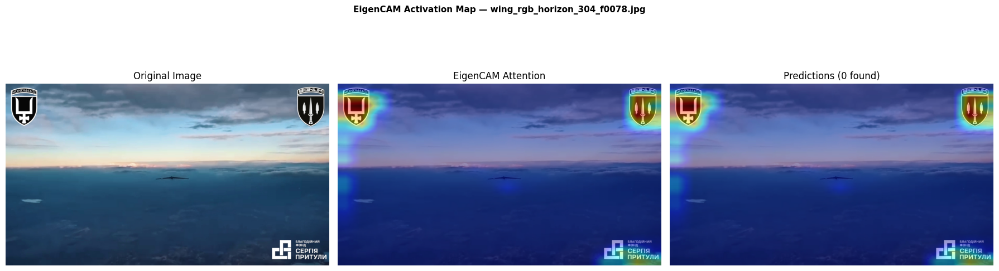

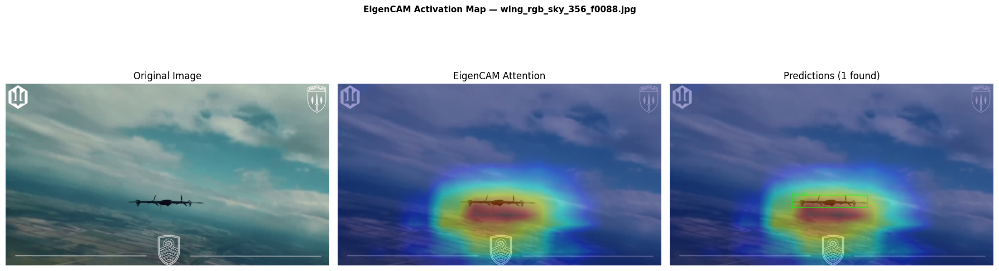

...

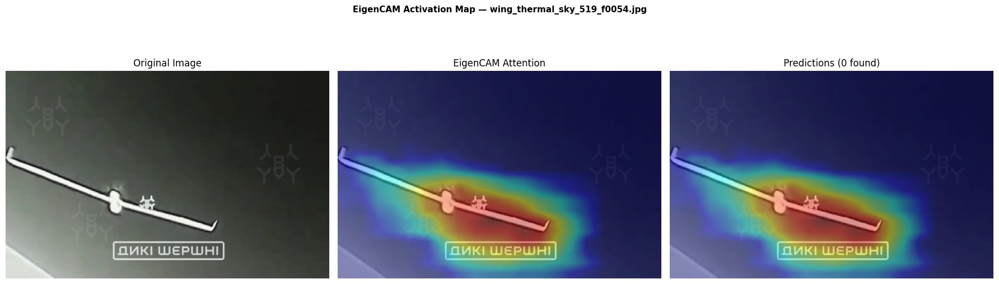

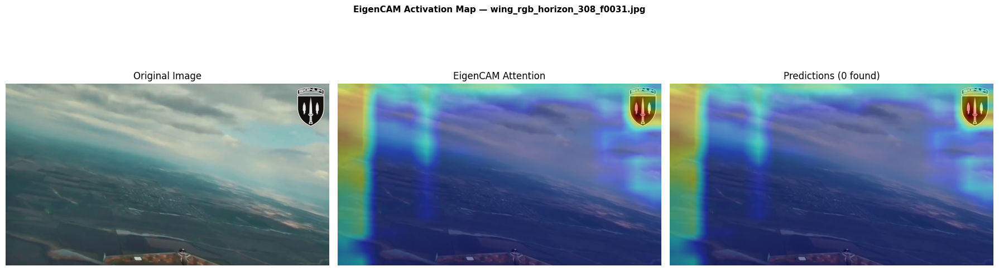

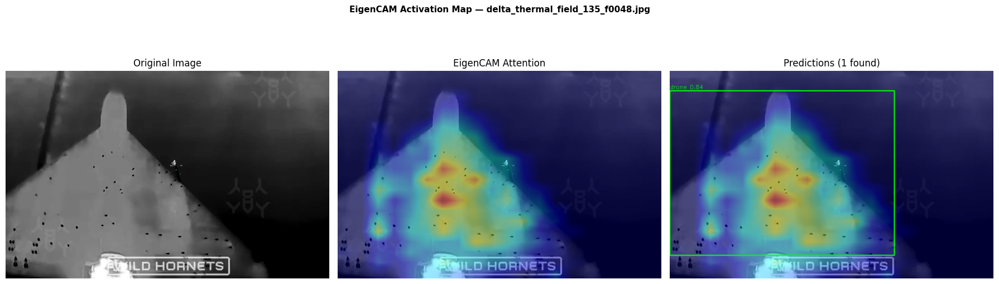

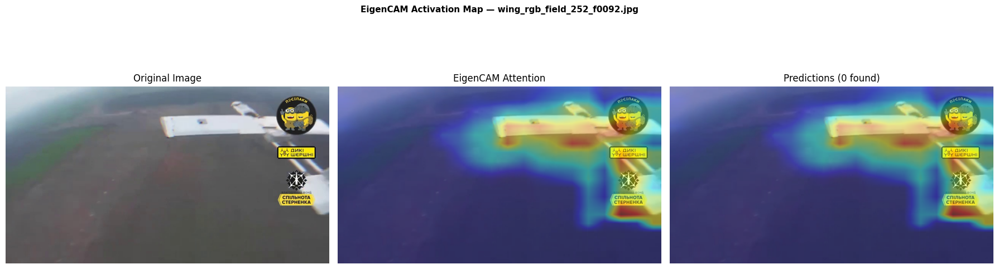

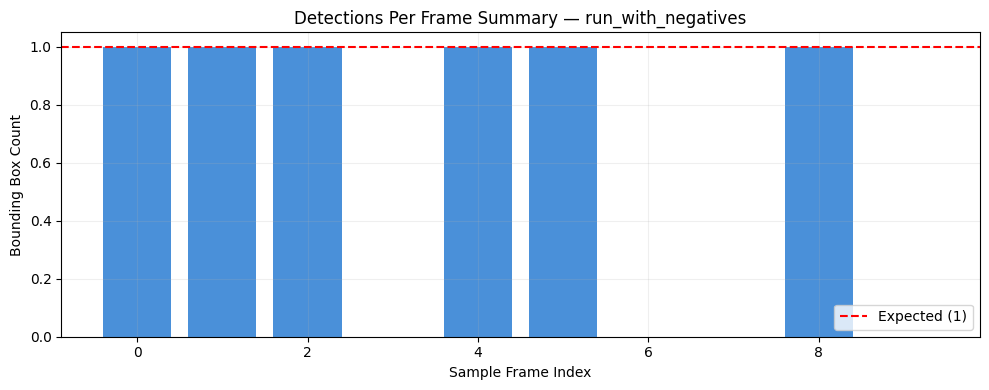


ANALYSIS REPORT: RUN_WITH_NEGATIVES
Frames Analyzed:            10
Average Detections/Frame:   0.60
Missed Objects:             4
Artifacts Saved To:         /kaggle/working/analysis_results/run_with_negatives


In [ ]:
# ==========================================
# RUN 2: Positives + Negatives Dataset
# ==========================================

run_name_2 = "run_with_negatives"

best_weights_2 = run_full_pipeline(
    use_negatives=True, 
    run_name=run_name_2,
    epochs=25,
    imgsz=IMGSZ,
    batch=BATCH_SIZE,
    patience=PATIENCE
)

val_dir_2 = WORKING_DIR / f"yolo_dataset_{run_name_2}" / "images" / "val"
run_shortcut_analysis(
    weights_path=str(best_weights_2),
    val_dir=str(val_dir_2),
    output_dir_path="/kaggle/working/analysis_results",
    run_name=run_name_2,
    n_images=10,
    conf_thresh=0.25
)

### **Final Model**

In [ ]:
# ==========================================
# RUN 3: Final Model
# ==========================================

run_name_3 = "final_model"

best_weights_3 = run_full_pipeline(
    use_negatives=True, 
    run_name=run_name_3,
    epochs=EPOCHS,
    imgsz=IMGSZ,
    batch=BATCH_SIZE,
    patience=PATIENCE
)


[DATA PREPARATION] Setting up dataset directories for run: final_model
[TRAIN] Symlinked 8,177 positives and 810 negatives.
[VAL] Symlinked 1,542 positives and 147 negatives.
[TEST] Symlinked 2,281 positives and 243 negatives.
[DATA PREPARATION] Created YAML configuration at: /kaggle/working/dataset_final_model.yaml

STARTING YOLO TRAINING RUN: FINAL_MODEL
Loading weights: yolo26n.pt
Ultralytics 8.4.70 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=disk, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/dataset_final_model.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchs

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

[SUCCESS] Checkpoint successfully uploaded to Hugging Face.

STARTING YOLO EVALUATION ON TEST DATA: FINAL_MODEL
Loading weights from: /kaggle/working/runs/detect/final_model/weights/best.pt
Ultralytics 8.4.70 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26n summary (fused): 122 layers, 2,375,031 parameters, 0 gradients, 5.2 GFLOPs
val: Fast image access ✅ (ping: 0.3±0.3 ms, read: 25.1±15.6 MB/s, size: 226.6 KB)
val: Scanning /kaggle/working/yolo_dataset_final_model/labels/test... 2281 images, 243 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2524/2524 177.5it/s 14.2s0.1s
val: New cache created: /kaggle/working/yolo_dataset_final_model/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 316/316 7.9it/s 39.8s0.1ss
                   all       2524       2281      0.889      0.814      0.867       0.67
Speed: 2.2ms preprocess, 10.5ms inference, 0.0ms loss, 0.1ms postprocess per image
Results saved